# 01 · Data understanding — Safia branch sales, 1–10 September 2026

**Question this notebook answers:** is `avg_sales_index` (the 10-day mean of daily `sales_index`) a sound
target for a location-quality model, and what exactly does it represent?

**Data** (`data/processed/`):

| file | grain | rows |
|---|---|---|
| `branches.csv` | one row per branch | 127 |
| `daily_performance.csv` | one row per branch × day | 1 270 |
| `dataset_metadata.csv` | how the indices were built | — |

All values are indices on one shared scale: daily sales after discounts ÷ the highest single-day sales of
*any* branch × 100 (same principle for orders; `avg_check_index` = branch sales ÷ orders, best branch = 100).

Sections: **1** Load · **2** Integrity · **3** Target distribution · **4** Target stability ·
**5** Temporal behaviour · **6** Target decomposition · **7** Geography · **8** Conclusions

## 1. Load data

In [ ]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

DATA_DIR = '../data/processed/'

# --- chart styling: one blue for single-series marks, orange only for the highlighted contrast series
BLUE, ORANGE = '#2a78d6', '#eb6834'
INK, INK2, MUTED, GRID, AXIS, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
BLUES = ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b']   # sequential ramp
BLUE_CMAP = mpl.colors.LinearSegmentedColormap.from_list('blues_seq', BLUES)

mpl.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'figure.dpi': 100, 'savefig.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': AXIS, 'axes.linewidth': 0.8,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.labelcolor': INK2, 'text.color': INK,
    'axes.titlecolor': INK, 'axes.titlesize': 11, 'axes.titlelocation': 'left', 'axes.titlepad': 10,
    'font.size': 9.5, 'legend.frameon': False, 'figure.constrained_layout.use': True,
})
pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 120)

In [27]:
branches = pd.read_csv(DATA_DIR + 'branches.csv')
daily = pd.read_csv(DATA_DIR + 'daily_performance.csv', parse_dates=['date'])
meta = pd.read_csv(DATA_DIR + 'dataset_metadata.csv')

print(f'branches: {branches.shape}    daily: {daily.shape}    '
      f'dates: {daily.date.min():%Y-%m-%d} … {daily.date.max():%Y-%m-%d} ({daily.date.nunique()} days)')
display(meta.set_index('key').loc[['included', 'sales_index', 'orders_index', 'avg_check_index', 'left_out']])
branches.head()

branches: (127, 10)    daily: (1270, 8)    dates: 2026-09-01 … 2026-09-10 (10 days)


,value
key,
included,127 stores with a location inside Uzbekistan and iiko sales on all 10 days
sales_index,"Daily sales after discounts (""Сумма со скидкой"" in iiko), divided by the highest single-day sales of any included br..."
orders_index,"Daily orders (""Заказов"" in iiko) on the same principle: highest single-day orders = 100."
avg_check_index,Each branch's 10-day sales ÷ orders; the highest branch = 100.
left_out,"14 with sales on only some days, 17 with no sales, 1 not in iiko, 68 without location, 14 with a wrong location (out..."


,branch_code,branch_name,format,city_approx,latitude,longitude,map_url,avg_sales_index,avg_orders_index,avg_check_index
0,W035,Мега,Safia,Tashkent,41.367122,69.291343,"https://www.google.com/maps?q=41.367122,69.291343",86.51,91.60,70.0
1,W025,Зенит,Safia,Tashkent,41.375005,69.271122,"https://www.google.com/maps?q=41.375005,69.271122",59.17,71.20,61.6
2,W016,МедГор,Safia,Tashkent,41.362609,69.187378,"https://www.google.com/maps?q=41.362609,69.187378",58.02,53.18,80.8
3,W026,Крестик,Safia,Tashkent,41.292597,69.356831,"https://www.google.com/maps?q=41.292597,69.356831",48.21,51.27,69.7
4,W037,Паркентская,Safia,Tashkent,41.312418,69.332706,"https://www.google.com/maps?q=41.312418,69.332706",46.45,52.49,65.6


## 2. Basic integrity checks

Each check is a one-line assertion on the files. The last three confirm that the provided branch-level
averages are exactly what we would recompute from the daily file, so there is no hidden extra processing.

In [28]:
recomputed = daily.groupby('branch_code').agg(mean_sales=('sales_index', 'mean'), mean_orders=('orders_index', 'mean'))
b = branches.set_index('branch_code').join(recomputed)
check_ratio = b.mean_sales / b.mean_orders

checks = {
    'no missing values (both files)': branches.isna().sum().sum() == 0 and daily.isna().sum().sum() == 0,
    'branch_code unique in branches.csv': branches.branch_code.is_unique,
    'one row per branch × date in daily file': not daily.duplicated(['branch_code', 'date']).any(),
    'every branch has exactly 10 days': (daily.groupby('branch_code').size() == 10).all(),
    'same 127 branches in both files': set(branches.branch_code) == set(daily.branch_code),
    'dates are 2026-09-01 … 2026-09-10, no gaps': daily.date.nunique() == 10 and (daily.date.max() - daily.date.min()).days == 9,
    'sales_index and orders_index within [0, 100]': daily.sales_index.between(0, 100).all() and daily.orders_index.between(0, 100).all(),
    'avg_sales_index == mean of the 10 daily sales_index': np.allclose(b.avg_sales_index, b.mean_sales),
    'avg_orders_index == mean of the 10 daily orders_index': np.allclose(b.avg_orders_index, b.mean_orders),
    'avg_check_index == (sales ÷ orders) scaled to max 100  (±0.2 rounding)': np.allclose(b.avg_check_index, check_ratio / check_ratio.max() * 100, atol=0.2),
}
display(pd.Series(checks).map({True: 'PASS', False: 'FAIL'}).to_frame('result'))
print('format:', branches['format'].value_counts().to_dict())
print('cities:', branches.city_approx.nunique(), '| branches in Tashkent:', (branches.city_approx == 'Tashkent').sum())

,result
no missing values (both files),PASS
branch_code unique in branches.csv,PASS
one row per branch × date in daily file,PASS
every branch has exactly 10 days,PASS
same 127 branches in both files,PASS
"dates are 2026-09-01 … 2026-09-10, no gaps",PASS
"sales_index and orders_index within [0, 100]",PASS
avg_sales_index == mean of the 10 daily sales_index,PASS
avg_orders_index == mean of the 10 daily orders_index,PASS
avg_check_index == (sales ÷ orders) scaled to max 100 (±0.2 rounding),PASS


format: {'Safia': 125, 'Safia mini': 2}
cities: 20 | branches in Tashkent: 102


## 3. Target distribution

`avg_sales_index` across the 127 branches: how spread out are branches on the 1–100 scale?

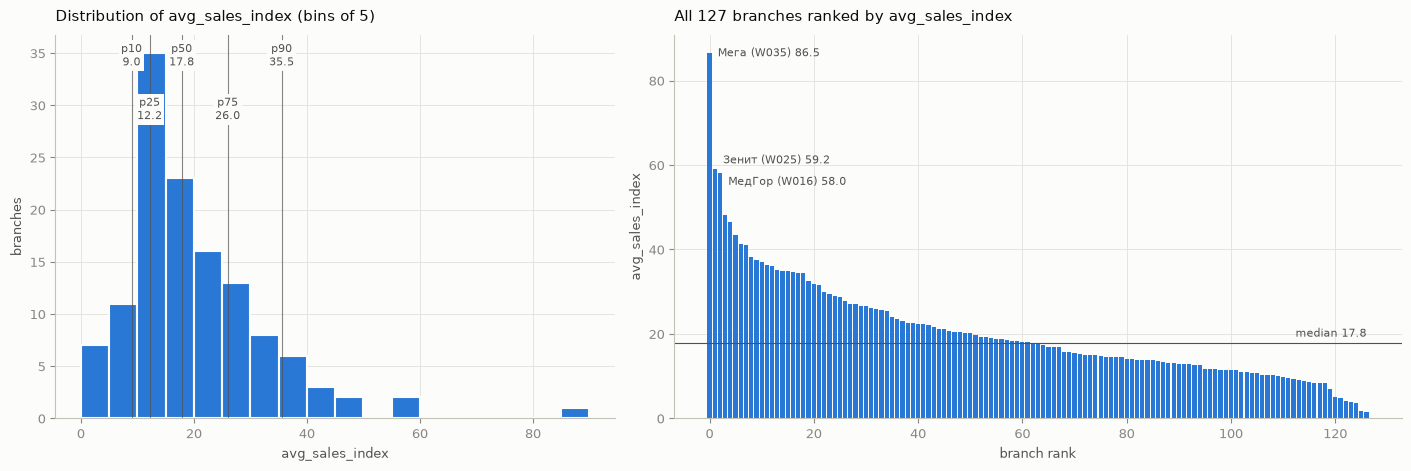

,min,max,mean,median,std,skewness,p10,p25,p50,p75,p90
avg_sales_index,1.61,86.51,20.36,17.84,12.52,1.86,8.96,12.16,17.84,25.98,35.52


In [29]:
target = branches.set_index('branch_code').avg_sales_index
pct = target.quantile([.10, .25, .50, .75, .90])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={'width_ratios': [1, 1.3]})

# left: histogram with percentile markers
ax1.hist(target, bins=np.arange(0, 95, 5), color=BLUE, edgecolor=SURFACE, linewidth=1.5)
ymax = ax1.get_ylim()[1]
for i, (q, v) in enumerate(pct.items()):
    ax1.axvline(v, color=INK2, lw=0.8, alpha=0.7)
    ax1.text(v, ymax * (0.98 if i % 2 == 0 else 0.84), f'p{int(q*100)}\n{v:.1f}', ha='center', va='top', fontsize=8, color=INK2,
             bbox=dict(facecolor=SURFACE, edgecolor='none', pad=1.5))
ax1.set(title='Distribution of avg_sales_index (bins of 5)', xlabel='avg_sales_index', ylabel='branches')

# right: every branch, ranked
srt = target.sort_values(ascending=False).reset_index(drop=True)
ax2.bar(srt.index, srt.values, width=0.8, color=BLUE)
ax2.axhline(target.median(), color=INK2, lw=0.8)
ax2.text(len(srt) - 1, target.median() + 1.5, f'median {target.median():.1f}', ha='right', fontsize=8, color=INK2)
for i, (code_, name, v) in enumerate(branches.nlargest(3, 'avg_sales_index')[['branch_code', 'branch_name', 'avg_sales_index']].itertuples(index=False)):
    ax2.annotate(f'{name} ({code_}) {v:.1f}', (i, v), xytext=(6, [0, 6, -6][i]), textcoords='offset points', fontsize=8, color=INK2, va='center')
ax2.set(title='All 127 branches ranked by avg_sales_index', xlabel='branch rank', ylabel='avg_sales_index')
plt.show()

pd.DataFrame({'avg_sales_index': [target.min(), target.max(), target.mean(), target.median(), target.std(), target.skew(), *pct]},
             index=['min', 'max', 'mean', 'median', 'std', 'skewness', 'p10', 'p25', 'p50', 'p75', 'p90']).T.round(2)

**What the plots show**

- The target is **strongly right-skewed** (skewness 1.9). Half of all branches sit between 12 and 26; the
  middle 10-point band (10–20) alone holds 58 of 127 branches.
- Only 8 branches exceed 40. **Мега (W035) at 86.5 is a lone outlier**, 27 points above the next branch
  (Зенит 59.2). Any model will be judged heavily on how it treats this one point.
- The low end is populated too: 18 branches are under 10, seven of them under 5.
- Practical consequence: errors should be assessed on a relative as well as an absolute basis, and a
  log or rank view of the target is worth keeping alongside the raw index.

### 3.1 Is 100 attainable at branch level?

The scale is anchored on the **highest single-day** sales of any branch, not the highest branch average.
A 10-day mean can therefore never reach 100 unless one branch hits the maximum on all 10 days.

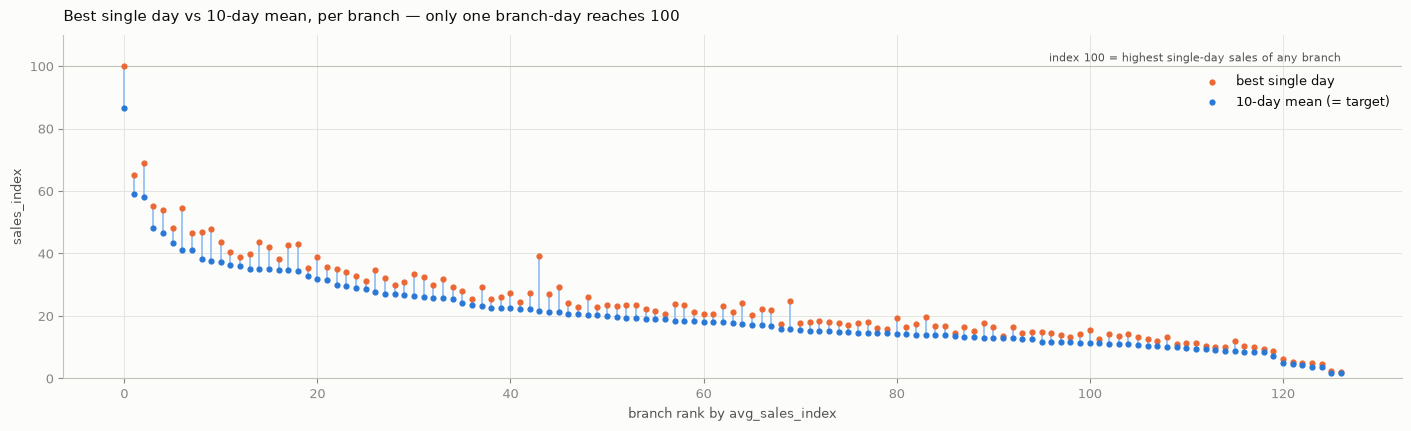

max daily sales_index   = 100.0   (Мега, Sat 05 Sep; reached once)
max avg_sales_index     = 86.51
best day of any other branch = 68.9
branch-days above 50: 2.9%   above 30: 18.0%


In [30]:
daily_max = daily.groupby('branch_code').sales_index.max()
order = target.sort_values(ascending=False).index
x = np.arange(len(order))

fig, ax = plt.subplots(figsize=(14, 4.2))
ax.vlines(x, target[order], daily_max[order], color=BLUES[1], lw=1.4)
ax.scatter(x, daily_max[order], s=12, color=ORANGE, zorder=3, label='best single day')
ax.scatter(x, target[order], s=12, color=BLUE, zorder=3, label='10-day mean (= target)')
ax.axhline(100, color=AXIS, lw=0.8)
ax.text(len(order) - 1, 101.5, 'index 100 = highest single-day sales of any branch', ha='right', fontsize=8, color=INK2)
ax.set(title='Best single day vs 10-day mean, per branch — only one branch-day reaches 100',
       xlabel='branch rank by avg_sales_index', ylabel='sales_index', ylim=(0, 110))
ax.legend(loc='upper right', bbox_to_anchor=(1, 0.92))
plt.show()

peak = daily.loc[daily.sales_index.idxmax()]
print(f'max daily sales_index   = {daily.sales_index.max():.1f}   ({peak.branch_name}, {peak.date:%a %d %b}; reached once)')
print(f'max avg_sales_index     = {target.max():.2f}')
print(f'best day of any other branch = {daily[daily.branch_code != target.idxmax()].sales_index.max():.1f}')
print(f'branch-days above 50: {(daily.sales_index > 50).mean():.1%}   above 30: {(daily.sales_index > 30).mean():.1%}')

**Takeaway:** training targets span **1.6 – 86.5**, not 1–100. The value 100 occurs exactly once in the
daily file (Мега, Saturday 5 Sep). Only 2.9 % of all branch-days exceed 50. A model predicting above ~90 is
extrapolating beyond anything observed.

## 4. Target stability

Is a branch's 10-day mean a faithful summary of its "normal" day, or is it distorted by one or two
unusual days? Per branch: mean, median, std, min, max, range and coefficient of variation (CV = std ÷ mean).

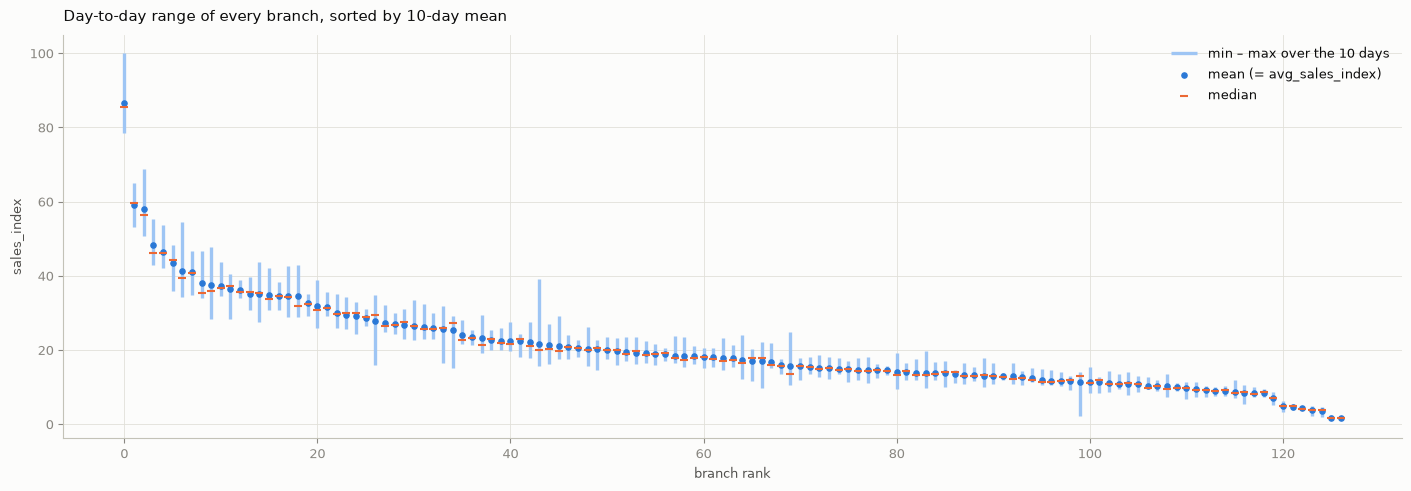

,mean_sales,median_sales,std_sales,min_sales,max_sales,range_sales,cv_sales
count,127.00,127.00,127.00,127.00,127.00,127.00,127.00
mean,20.36,20.12,2.37,16.98,24.35,7.37,0.13
std,12.52,12.37,1.46,11.34,14.54,4.47,0.05
min,1.61,1.60,0.29,1.10,2.10,1.00,0.04
25%,12.16,12.08,1.32,9.90,14.60,4.25,0.09
50%,17.84,17.40,1.96,14.50,21.20,6.00,0.11
75%,25.98,26.20,3.01,22.20,31.05,9.50,0.15
max,86.51,85.50,7.15,78.40,100.00,23.40,0.34


In [31]:
stab = daily.groupby('branch_code').sales_index.agg(mean_sales='mean', median_sales='median', std_sales='std',
                                                    min_sales='min', max_sales='max')
stab['range_sales'] = stab.max_sales - stab.min_sales
stab['cv_sales'] = stab.std_sales / stab.mean_sales
stab = stab.join(branches.set_index('branch_code')[['branch_name', 'city_approx']])

s = stab.sort_values('mean_sales', ascending=False).reset_index()
x = np.arange(len(s))

fig, ax = plt.subplots(figsize=(14, 4.8))
ax.vlines(x, s.min_sales, s.max_sales, color=BLUES[1], lw=2.4, label='min – max over the 10 days')
ax.scatter(x, s.mean_sales, s=14, color=BLUE, zorder=3, label='mean (= avg_sales_index)')
ax.scatter(x, s.median_sales, s=40, marker='_', color=ORANGE, zorder=4, label='median')
ax.set(title='Day-to-day range of every branch, sorted by 10-day mean', xlabel='branch rank', ylabel='sales_index')
ax.legend(loc='upper right')
plt.show()

stab[['mean_sales', 'median_sales', 'std_sales', 'min_sales', 'max_sales', 'range_sales', 'cv_sales']].describe().round(2)

**What the plot shows**

- Day-to-day ranges are **narrow relative to the gaps between branches**: the median branch has a std of
  2.0 index points and a min–max range of 6.0, while the inter-quartile spread of the *means* is 14 points.
- Volatility scales with level (bigger branches swing more in absolute terms), but the relative
  noise is modest: median CV ≈ 11 %, three-quarters of branches below 15 %.
- Mean and median markers almost coincide for nearly every branch — quantified next.

### 4.1 Mean vs median

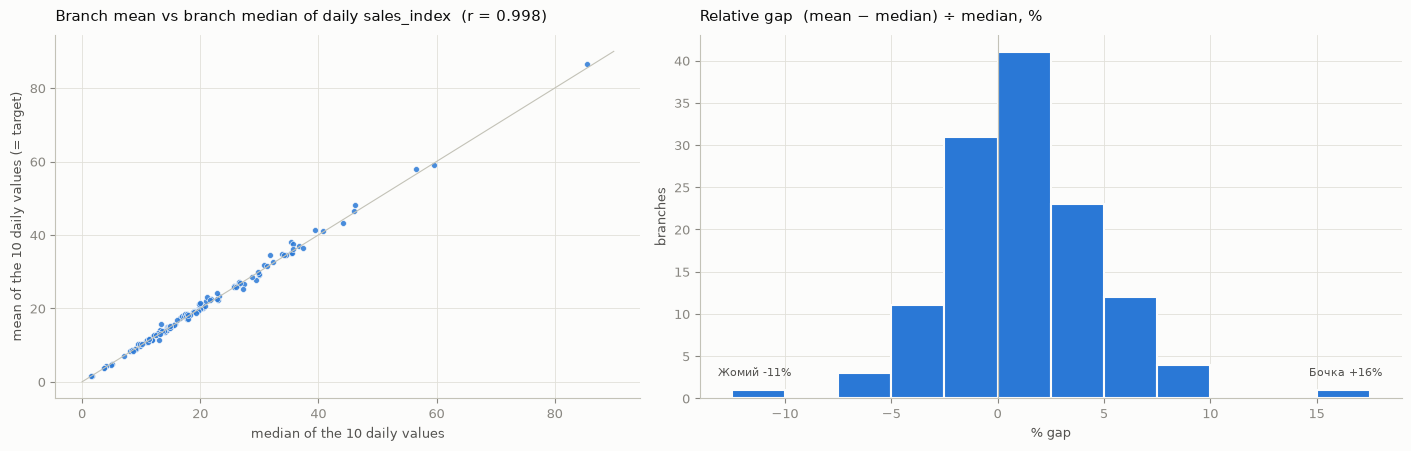

branches with |gap| > 5 %: 21 of 127     |gap| > 10 %: 2


,branch_name,city_approx,mean_sales,median_sales,gap,gap_pct,std_sales
branch_code,,,,,,,
W173,Бочка,near Gazalkent (16 km),15.65,13.45,2.20,16.36,5.31
W076,Жомий,Tashkent,11.47,12.95,-1.48,-11.43,3.77
W098,Корасув,Tashkent,23.10,21.20,1.90,8.96,4.01
W092,Янги Хаёт,Tashkent,34.47,31.85,2.62,8.23,5.63
W078,Келес,Keles,10.17,9.40,0.77,8.19,2.30
W214,Матонат,Tashkent,21.59,20.05,1.54,7.68,6.80
W099,Сайрам,Tashkent,38.10,35.45,2.65,7.48,5.13
W091,Эко (Chimgan),Tashkent,14.14,13.20,0.94,7.12,3.32


In [32]:
rel_gap = (stab.mean_sales - stab.median_sales) / stab.median_sales * 100
r_mm = stab.mean_sales.corr(stab.median_sales)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={'width_ratios': [1, 1.2]})
ax1.plot([0, 90], [0, 90], color=AXIS, lw=0.8)
ax1.scatter(stab.median_sales, stab.mean_sales, s=18, color=BLUE, alpha=0.85, edgecolor=SURFACE, linewidth=0.5)
ax1.set(title=f'Branch mean vs branch median of daily sales_index  (r = {r_mm:.3f})',
        xlabel='median of the 10 daily values', ylabel='mean of the 10 daily values (= target)')

ax2.hist(rel_gap, bins=np.arange(-12.5, 20, 2.5), color=BLUE, edgecolor=SURFACE, linewidth=1.5)
ax2.axvline(0, color=AXIS, lw=0.8)
for code_, v in rel_gap[rel_gap.abs() > 10].items():
    ax2.annotate(f'{stab.loc[code_, "branch_name"]} {v:+.0f}%', (v, 1), xytext=(0, 10), textcoords='offset points',
                 ha='center', fontsize=8, color=INK2)
ax2.set(title='Relative gap  (mean − median) ÷ median, %', xlabel='% gap', ylabel='branches')
plt.show()

print(f'branches with |gap| > 5 %: {(rel_gap.abs() > 5).sum()} of 127     |gap| > 10 %: {(rel_gap.abs() > 10).sum()}')
(stab.assign(gap=stab.mean_sales - stab.median_sales, gap_pct=rel_gap)
     .reindex(rel_gap.abs().sort_values(ascending=False).index)
     [['branch_name', 'city_approx', 'mean_sales', 'median_sales', 'gap', 'gap_pct', 'std_sales']].head(8).round(2))

**What the plots show**

- Mean and median agree almost perfectly: r = 0.998, and the typical gap is **+1 %** (means sit slightly
  above medians because the few unusual days are mostly *high* days — see Section 5).
- 21 branches differ by more than 5 %, only two by more than 10 %: **Бочка** (+16 %, three strong
  holiday/weekend days) and **Жомий** (−11 %, two collapsed days at the end of the period).
- Using the mean rather than the median changes the target by < 1 point for 108 of 127 branches, so the
  provided `avg_sales_index` is a defensible target. The median is kept as a robustness check.

### 4.2 Unusually volatile branches

Sorted by CV (std ÷ mean). CV is inflated for very small branches (a 0.4-point std on a mean of 1.7 is a
23 % CV), so the std-vs-mean view and the raw daily series are shown together.

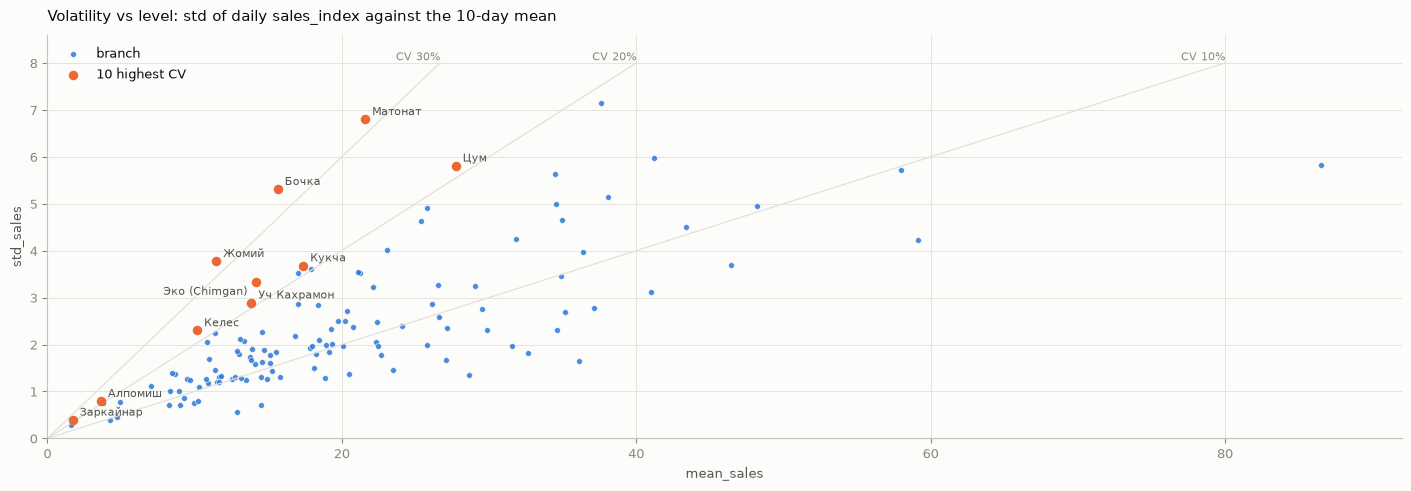

In [33]:
vol = stab.sort_values('cv_sales', ascending=False).head(10)

fig, ax = plt.subplots(figsize=(14, 4.8))
for cv in (0.10, 0.20, 0.30):
    x_end = min(92, 8.0 / cv)
    ax.plot([0, x_end], [0, x_end * cv], color=GRID, lw=0.9)
    ax.text(x_end, x_end * cv, f'CV {cv:.0%}', fontsize=8, color=MUTED, va='bottom', ha='right')
ax.scatter(stab.mean_sales, stab.std_sales, s=18, color=BLUE, alpha=0.85, edgecolor=SURFACE, linewidth=0.5, label='branch')
ax.scatter(vol.mean_sales, vol.std_sales, s=34, color=ORANGE, zorder=3, label='10 highest CV')
label_pos = {'Эко (Chimgan)': (-6, -9, 'right')}          # manual nudge where labels would collide
for code_, r in vol.iterrows():
    dx, dy, ha = label_pos.get(r.branch_name, (5, 3, 'left'))
    ax.annotate(r.branch_name, (r.mean_sales, r.std_sales), xytext=(dx, dy), textcoords='offset points', fontsize=8, color=INK2, ha=ha)
ax.set(title='Volatility vs level: std of daily sales_index against the 10-day mean',
       xlabel='mean_sales', ylabel='std_sales', xlim=(0, 92), ylim=(0, 8.6))
ax.legend(loc='upper left')
plt.show()

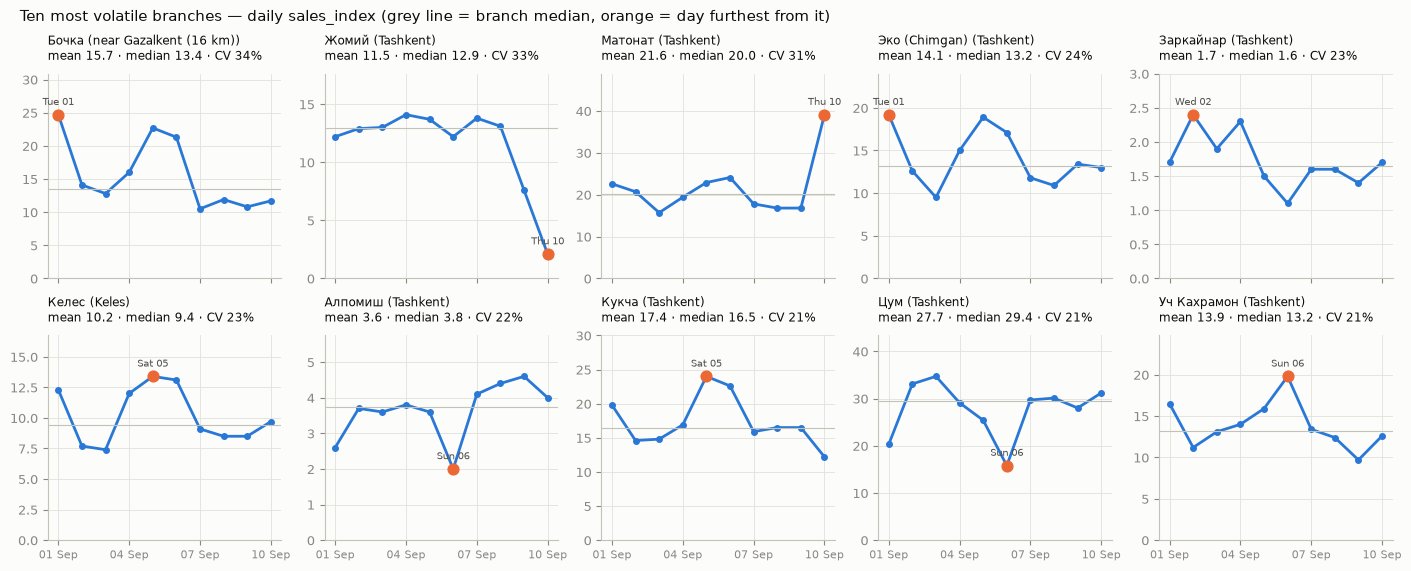

,branch_name,city_approx,mean_sales,median_sales,std_sales,min_sales,max_sales,range_sales,cv_sales
branch_code,,,,,,,,,
W173,Бочка,near Gazalkent (16 km),15.65,13.45,5.31,10.5,24.7,14.2,0.34
W076,Жомий,Tashkent,11.47,12.95,3.77,2.1,14.1,12.0,0.33
W214,Матонат,Tashkent,21.59,20.05,6.80,15.7,39.1,23.4,0.31
W091,Эко (Chimgan),Tashkent,14.14,13.20,3.32,9.5,19.2,9.7,0.24
W172,Заркайнар,Tashkent,1.72,1.65,0.39,1.1,2.4,1.3,0.23
W078,Келес,Keles,10.17,9.40,2.30,7.4,13.4,6.0,0.23
W210,Алпомиш,Tashkent,3.64,3.75,0.79,2.0,4.6,2.6,0.22
W034,Кукча,Tashkent,17.38,16.50,3.68,12.2,24.0,11.8,0.21
W030,Цум,Tashkent,27.74,29.40,5.81,15.8,34.7,18.9,0.21


In [34]:
piv = daily.pivot(index='branch_code', columns='date', values='sales_index')
dates = piv.columns

fig, axes = plt.subplots(2, 5, figsize=(14, 5.6), sharex=True)
for ax, (code_, r) in zip(axes.flat, vol.iterrows()):
    y = piv.loc[code_]
    odd_day = (y - r.median_sales).abs().idxmax()
    ax.plot(dates, y, color=BLUE, lw=2, marker='o', ms=4)
    ax.axhline(r.median_sales, color=AXIS, lw=0.8)
    ax.scatter([odd_day], [y[odd_day]], s=60, color=ORANGE, zorder=3)
    ax.annotate(f'{odd_day:%a %d}', (odd_day, y[odd_day]), xytext=(0, 7), textcoords='offset points', ha='center', fontsize=7.5, color=INK2)
    ax.set_title(f'{r.branch_name} ({r.city_approx})\nmean {r.mean_sales:.1f} · median {r.median_sales:.1f} · CV {r.cv_sales:.0%}', fontsize=8.5)
    ax.set_xticks(dates[::3]); ax.set_xticklabels([d.strftime('%d %b') for d in dates[::3]], fontsize=8)
    ax.set_ylim(0, y.max() * 1.25)
fig.suptitle('Ten most volatile branches — daily sales_index (grey line = branch median, orange = day furthest from it)',
             x=0.01, ha='left', fontsize=11)
plt.show()

vol[['branch_name', 'city_approx', 'mean_sales', 'median_sales', 'std_sales', 'min_sales', 'max_sales', 'range_sales', 'cv_sales']].round(2)

**What the small multiples show** — the volatility has three distinct shapes, and none of them looks like
random noise:

- **Leisure / holiday pattern** — Бочка (16 km from Gazalkent, towards the mountains) and Эко (Chimgan)
  peak on 1 Sep (Independence Day), Sat 5 and Sun 6, and are quiet on working days. Their 10-day mean is
  a blend of two regimes rather than a "normal day".
- **Probable closure or partial trading day** — Жомий falls from ~13 to 7.6 and then 2.1 on 9–10 Sep;
  Цум has one day at 15.8 against a median of 29.4. These look operational (or data) events, not demand.
- **One-off spike** — Матонат records 39.1 on Wed 10 Sep against a median of 20 (possibly a bulk order
  or promotion).
- Заркайнар and Алпомиш appear only because their means are tiny (1.7 and 3.6); in absolute terms they
  barely move.

None of these is severe enough to change the target choice, but the branches above are flagged as
**noisier labels** and are candidates for a robustness check (e.g. refit with median targets, or
down-weight them).

## 5. Temporal behaviour

Only ten consecutive days are available (Tue 1 Sep – Thu 10 Sep 2026, one full weekend). Two questions:
does the calendar move all branches together, and does the *ranking* of branches survive from day to day?

### 5.1 Average sales by date

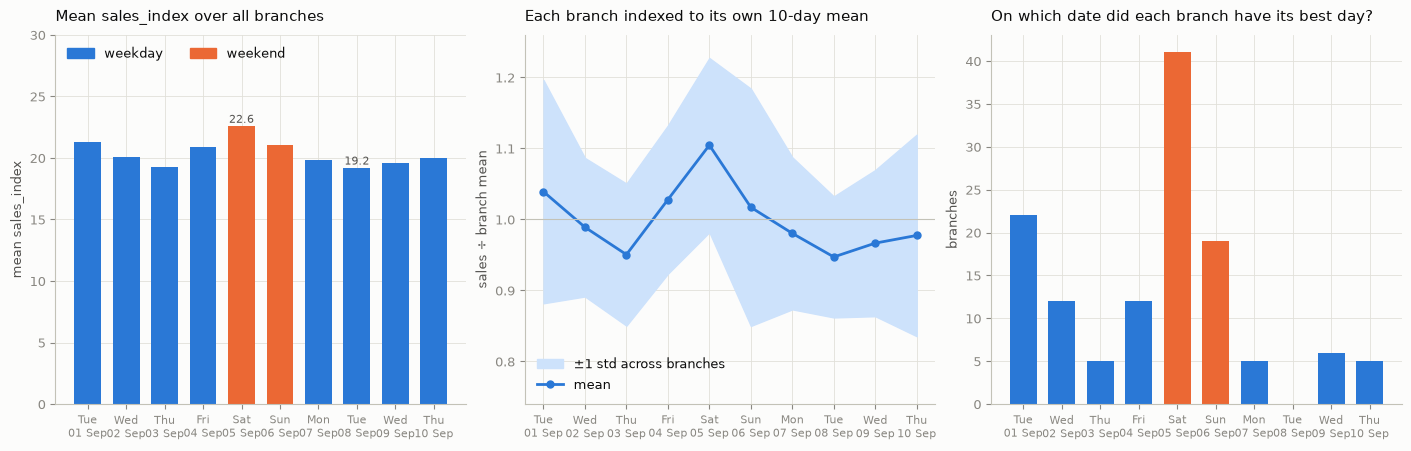

weekday mean 20.00   weekend mean 21.82
share of within-branch variance explained by a common date effect: 12.5%


In [35]:
by_date = daily.groupby('date').sales_index.mean()
daily['rel'] = daily.sales_index / daily.groupby('branch_code').sales_index.transform('mean')
rel_by_date = daily.groupby('date').rel.agg(['mean', 'std'])
labels = [d.strftime('%a\n%d %b') for d in by_date.index]
is_weekend = by_date.index.dayofweek >= 5
best_day = daily.loc[daily.groupby('branch_code').sales_index.idxmax()].date.value_counts().sort_index()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
ax1, ax2, ax3 = axes
ax1.bar(range(10), by_date.values, color=[ORANGE if w else BLUE for w in is_weekend], width=0.7)
for i in (by_date.values.argmax(), by_date.values.argmin()):
    ax1.text(i, by_date.values[i] + 0.3, f'{by_date.values[i]:.1f}', ha='center', fontsize=8, color=INK2)
ax1.set(title='Mean sales_index over all branches', ylabel='mean sales_index', ylim=(0, 30))
ax1.legend(handles=[Patch(color=BLUE, label='weekday'), Patch(color=ORANGE, label='weekend')], loc='upper left', ncols=2)

ax2.fill_between(range(10), rel_by_date['mean'] - rel_by_date['std'], rel_by_date['mean'] + rel_by_date['std'], color=BLUES[0], label='±1 std across branches')
ax2.plot(range(10), rel_by_date['mean'], color=BLUE, lw=2, marker='o', ms=5, label='mean')
ax2.axhline(1, color=AXIS, lw=0.8)
ax2.set(title='Each branch indexed to its own 10-day mean', ylabel='sales ÷ branch mean', ylim=(0.74, 1.26))
ax2.legend(loc='lower left')

ax3.bar(range(10), best_day.reindex(by_date.index).fillna(0).values, color=[ORANGE if w else BLUE for w in is_weekend], width=0.7)
ax3.set(title='On which date did each branch have its best day?', ylabel='branches')

for ax in axes:
    ax.set_xticks(range(10)); ax.set_xticklabels(labels, fontsize=8)
plt.show()

print(f"weekday mean {daily.loc[~daily.date.dt.dayofweek.ge(5), 'sales_index'].mean():.2f}   "
      f"weekend mean {daily.loc[daily.date.dt.dayofweek.ge(5), 'sales_index'].mean():.2f}")
resid_var = (daily.rel - daily.groupby('date').rel.transform('mean')).var()
print(f'share of within-branch variance explained by a common date effect: {1 - resid_var / daily.rel.var():.1%}')

**What the plots show**

- A **mild common calendar effect**: Saturday 5 Sep is the strongest day everywhere (+10 % vs each
  branch's own mean; 41 of 127 branches had their best day then), Thursday 3 and Tuesday 8 the weakest
  (−5 %). Weekend average 21.8 vs weekday 20.0.
- **Tuesday 1 Sep behaves like a weekend day** (+4 %, 22 best-days). It is Independence Day in
  Uzbekistan, a public holiday, which is consistent with the pattern.
- The effect is real but small: a shared date factor explains only ~12 % of the day-to-day variation
  within branches. The 10-day mean therefore contains a modest calendar mix (2 weekend days + 1 holiday out
  of 10, i.e. slightly more "leisure" days than a typical week). No correction is applied; it is documented.

### 5.2 Does the branch ranking stay stable between days?

Spearman rank correlation between every pair of days, rank paths of the top 10 branches, and how far each
branch's daily rank moves over the period.

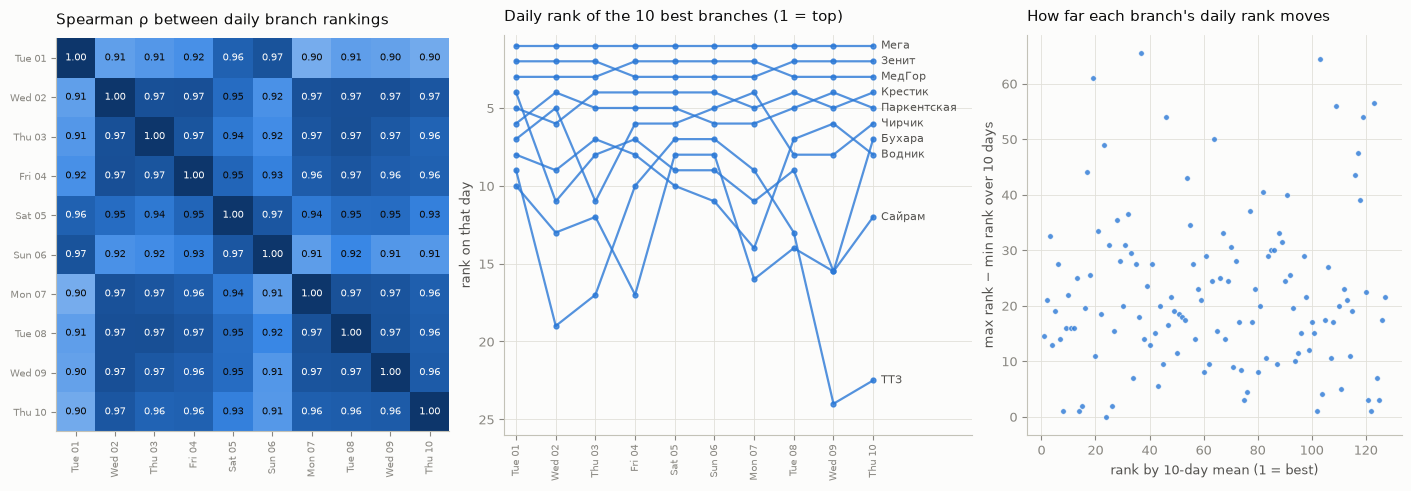

pairwise Spearman between days:  min 0.896   mean 0.946   max 0.974
Spearman of each day vs the 10-day mean: {'Tue 01': 0.953, 'Wed 02': 0.983, 'Thu 03': 0.98, 'Fri 04': 0.983, 'Sat 05': 0.977, 'Sun 06': 0.96, 'Mon 07': 0.975, 'Tue 08': 0.981, 'Wed 09': 0.978, 'Thu 10': 0.973}
median rank movement per branch: 20 positions of 127;  branches whose daily rank never leaves the same quartile: 53 of 127


In [36]:
rank_corr = piv.corr(method='spearman')
ranks = piv.rank(ascending=False)
rank_range = ranks.max(axis=1) - ranks.min(axis=1)
overall_rank = target.rank(ascending=False)
day_lbl = [d.strftime('%a %d') for d in dates]
top10 = target.sort_values(ascending=False).head(10).index
names = branches.set_index('branch_code').branch_name

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1.05, 1.25, 1]})

im = ax1.imshow(rank_corr.values, cmap=BLUE_CMAP, vmin=0.85, vmax=1.0)
for i in range(10):
    for j in range(10):
        v = rank_corr.values[i, j]
        ax1.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7, color=SURFACE if v > 0.955 else INK)
ax1.set_xticks(range(10)); ax1.set_xticklabels(day_lbl, rotation=90, fontsize=7.5)
ax1.set_yticks(range(10)); ax1.set_yticklabels(day_lbl, fontsize=7.5)
ax1.grid(False); ax1.set_title('Spearman ρ between daily branch rankings')

for code_ in top10:
    ax2.plot(range(10), ranks.loc[code_], color=BLUE, lw=1.6, marker='o', ms=3.5, alpha=0.8)
    ax2.text(9.2, ranks.loc[code_].iloc[-1], names[code_], va='center', fontsize=8, color=INK2)
ax2.set_xticks(range(10)); ax2.set_xticklabels(day_lbl, rotation=90, fontsize=7.5)
ax2.set_ylim(26, 0.3); ax2.set_xlim(-0.3, 11.5)
ax2.set(title='Daily rank of the 10 best branches (1 = top)', ylabel='rank on that day')

ax3.scatter(overall_rank, rank_range, s=16, color=BLUE, alpha=0.8, edgecolor=SURFACE, linewidth=0.5)
ax3.set(title='How far each branch\'s daily rank moves', xlabel='rank by 10-day mean (1 = best)', ylabel='max rank − min rank over 10 days')
plt.show()

off_diag = rank_corr.values[np.triu_indices(10, k=1)]
day_vs_mean = {lbl: round(float(piv[d].rank().corr(target.rank())), 3) for lbl, d in zip(day_lbl, dates)}
print(f'pairwise Spearman between days:  min {off_diag.min():.3f}   mean {off_diag.mean():.3f}   max {off_diag.max():.3f}')
print('Spearman of each day vs the 10-day mean:', day_vs_mean)
print(f'median rank movement per branch: {rank_range.median():.0f} positions of 127;  '
      f'branches whose daily rank never leaves the same quartile: {(piv.apply(lambda c: pd.qcut(c, 4, labels=False)).nunique(axis=1) == 1).sum()} of 127')

**What the plots show**

- **Rankings are highly persistent**: every pair of days correlates at ρ = 0.90–0.97 (mean 0.95), and every
  single day correlates at ρ ≥ 0.95 with the 10-day mean. Location-specific performance clearly exists and is
  visible even in one day of data.
- The three "leisure" days (Tue 1, Sat 5, Sun 6) form their own block — they correlate at 0.96–0.97 with
  each other but only 0.90–0.95 with working days. The ranking that shifts is the *leisure vs workday* mix,
  not random reshuffling.
- The top 3 (Мега, Зенит, МедГор) never leave the top 3. Movement is largest in the **middle of the
  distribution** (ranks ~30–90, where branches sit 1–2 points apart) and small at both ends.
- Only 10 days are observed, so the ranking's stability across *seasons* cannot be checked. This is the main
  caveat on the target.

## 6. Target decomposition — sales vs orders vs average check

Sales ≈ orders × average check. Is a high-sales branch one with many orders, large tickets, or both?

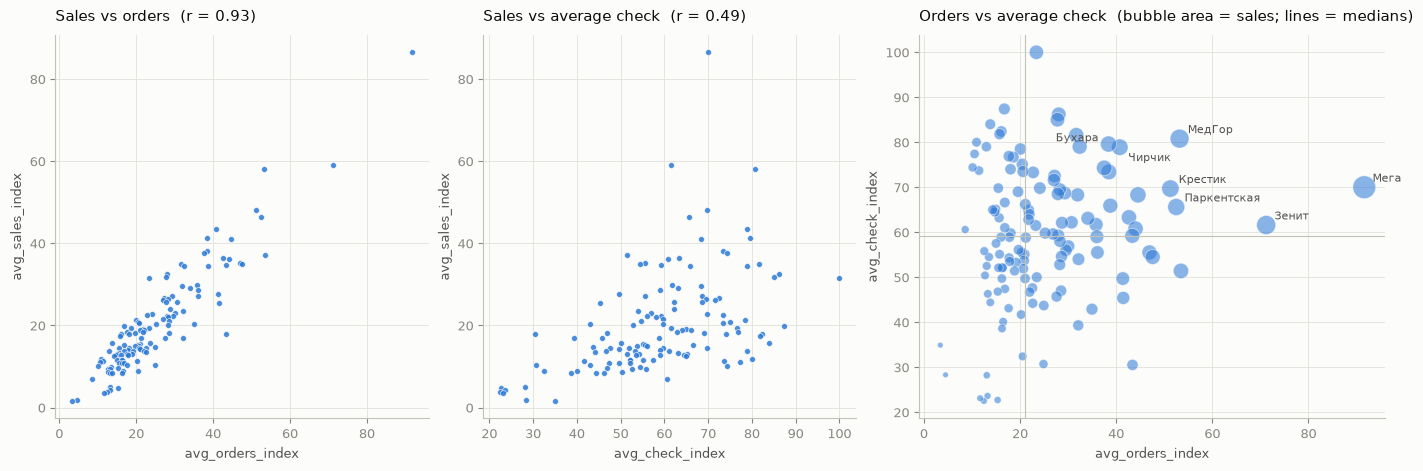

,share of var(log sales)
orders (volume),0.602
average check (ticket size),0.211
"2 × cov(orders, check)",0.186


count                                  mean                   
check               check above median check below median check above median check below median
orders                                                                                         
orders above median                 37                 26               33.2               22.0
orders below median                 26                 38               15.4               10.1

In [37]:
bb = branches
r_o = bb.avg_sales_index.corr(bb.avg_orders_index)
r_c = bb.avg_sales_index.corr(bb.avg_check_index)
med_o, med_c = bb.avg_orders_index.median(), bb.avg_check_index.median()

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4.6), gridspec_kw={'width_ratios': [1, 1, 1.25]})
ax1.scatter(bb.avg_orders_index, bb.avg_sales_index, s=18, color=BLUE, alpha=0.85, edgecolor=SURFACE, linewidth=0.5)
ax1.set(title=f'Sales vs orders  (r = {r_o:.2f})', xlabel='avg_orders_index', ylabel='avg_sales_index')
ax2.scatter(bb.avg_check_index, bb.avg_sales_index, s=18, color=BLUE, alpha=0.85, edgecolor=SURFACE, linewidth=0.5)
ax2.set(title=f'Sales vs average check  (r = {r_c:.2f})', xlabel='avg_check_index', ylabel='avg_sales_index')

ax3.axvline(med_o, color=AXIS, lw=0.8); ax3.axhline(med_c, color=AXIS, lw=0.8)
ax3.scatter(bb.avg_orders_index, bb.avg_check_index, s=12 + bb.avg_sales_index * 3, color=BLUE, alpha=0.55, edgecolor=SURFACE, linewidth=0.6)
label_pos = {'Бухара': (-7, 2, 'right'), 'Чирчик': (6, -10, 'left')}   # manual nudge where labels would collide
for _, r in bb.nlargest(7, 'avg_sales_index').iterrows():
    dx, dy, ha = label_pos.get(r.branch_name, (6, 4, 'left'))
    ax3.annotate(r.branch_name, (r.avg_orders_index, r.avg_check_index), xytext=(dx, dy), textcoords='offset points', fontsize=8, color=INK2, ha=ha)
ax3.set(title='Orders vs average check  (bubble area = sales; lines = medians)', xlabel='avg_orders_index', ylabel='avg_check_index')
plt.show()

# variance of log(sales) = var(log orders) + var(log check) + 2 cov  (check index is sales ÷ orders, rescaled)
ls, lo, lc = np.log(bb.avg_sales_index), np.log(bb.avg_orders_index), np.log(bb.avg_check_index)
shares = pd.Series({'orders (volume)': lo.var() / ls.var(), 'average check (ticket size)': lc.var() / ls.var(),
                    '2 × cov(orders, check)': 2 * lo.cov(lc) / ls.var()}, name='share of var(log sales)').round(3)
display(shares.to_frame())

quad = (bb.assign(orders=np.where(bb.avg_orders_index > med_o, 'orders above median', 'orders below median'),
                  check=np.where(bb.avg_check_index > med_c, 'check above median', 'check below median'))
          .pivot_table(index='orders', columns='check', values='avg_sales_index', aggfunc=['count', 'mean']).round(1))
quad

**What the plots show**

- The sales index is **primarily a volume index**: r = 0.93 with orders, and order volume accounts for
  ~60 % of the variance of log-sales (ticket size ~21 %, their covariance ~19 %).
- Ticket size still matters: branches with high orders *and* high checks average 33 on the target; high
  orders with low checks average 22; low orders with high checks only 15.
- Two routes to the same sales level are visible in the bubble chart. Мега, Зенит, Ганга, СамПИ run on
  volume with ordinary or small tickets (central Tashkent, footfall locations). МедГор, Бухара, Чирчик,
  Карши, Коканд run on fewer but larger orders — regional branches have systematically higher checks
  (median check index 72 outside Tashkent vs 57 inside).
- For a location model this suggests the *orders* index is the component most tied to catchment and
  footfall, while the check index carries a regional / format component. Both will be worth predicting
  (or at least inspecting) separately.

## 7. Geographic overview

`city_approx` is the nearest city centre (orientation only). 102 of the 127 branches are in Tashkent;
the other 25 are spread over 19 cities, mostly one branch each.

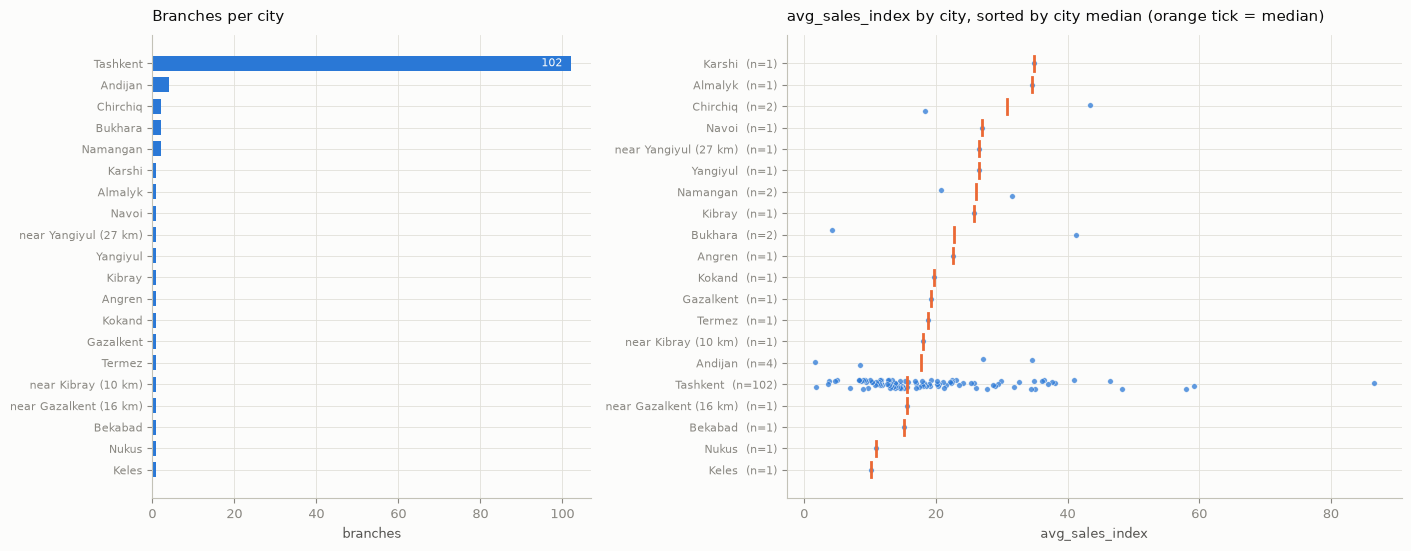

avg_sales_index              avg_orders_index              avg_check_index             
                       count median  mean            count median  mean           count median  mean
region                                                                                              
Tashkent                 102   15.7  19.9              102   21.1  25.3             102   56.5  56.9
other cities              25   20.7  22.3               25   21.1  23.4              25   72.5  68.4

In [38]:
city_counts = branches.city_approx.value_counts()
city_order = branches.groupby('city_approx').avg_sales_index.median().sort_values().index
rng = np.random.default_rng(0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={'width_ratios': [1, 1.4]})
ax1.barh(city_counts.index[::-1], city_counts.values[::-1], color=BLUE, height=0.7)
ax1.text(city_counts.iloc[0] - 2, len(city_counts) - 1, f'{city_counts.iloc[0]}', ha='right', va='center', fontsize=8, color=SURFACE)
ax1.set(title='Branches per city', xlabel='branches'); ax1.tick_params(axis='y', labelsize=8)

for i, c in enumerate(city_order):
    v = branches.loc[branches.city_approx == c, 'avg_sales_index']
    jitter = rng.uniform(-0.22, 0.22, len(v)) if len(v) > 1 else np.zeros(len(v))
    ax2.scatter(v, i + jitter, s=16, color=BLUE, alpha=0.75, edgecolor=SURFACE, linewidth=0.4)
    ax2.plot([v.median()] * 2, [i - 0.35, i + 0.35], color=ORANGE, lw=2)
ax2.set_yticks(range(len(city_order))); ax2.set_yticklabels([f'{c}  (n={city_counts[c]})' for c in city_order], fontsize=8)
ax2.set(title='avg_sales_index by city, sorted by city median (orange tick = median)', xlabel='avg_sales_index')
plt.show()

(branches.assign(region=np.where(branches.city_approx == 'Tashkent', 'Tashkent', 'other cities'))
         .groupby('region')[['avg_sales_index', 'avg_orders_index', 'avg_check_index']]
         .agg(['count', 'median', 'mean']).round(1))

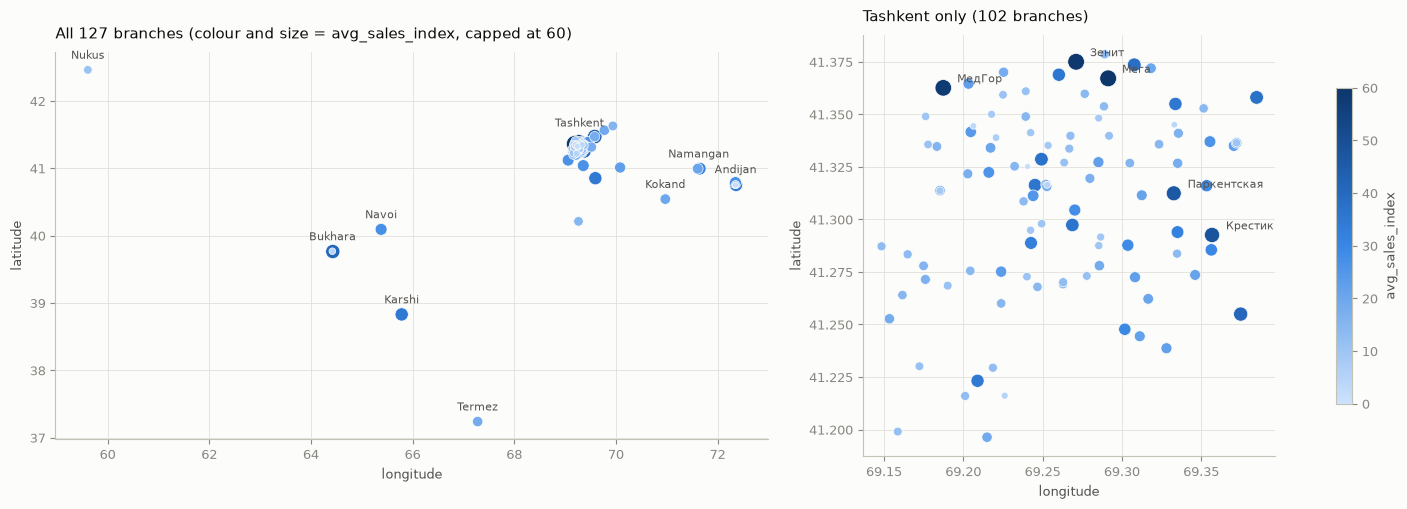

In [39]:
far_cities = ['Nukus', 'Bukhara', 'Navoi', 'Karshi', 'Termez', 'Kokand', 'Namangan', 'Andijan']
tash = branches[branches.city_approx == 'Tashkent']
norm = mpl.colors.Normalize(vmin=0, vmax=60)
aspect = 1 / np.cos(np.radians(41))      # 1° of latitude ≈ 1.33° of longitude at this latitude

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1.7, 1]})
for ax, df, title in [(ax1, branches, 'All 127 branches (colour and size = avg_sales_index, capped at 60)'),
                      (ax2, tash, f'Tashkent only ({len(tash)} branches)')]:
    sc = ax.scatter(df.longitude, df.latitude, c=df.avg_sales_index, cmap=BLUE_CMAP, norm=norm,
                    s=14 + df.avg_sales_index.clip(upper=60) * 2.2, edgecolor=SURFACE, linewidth=0.5)
    ax.set(title=title, xlabel='longitude', ylabel='latitude'); ax.set_aspect(aspect)
for c in far_cities:
    p = branches[branches.city_approx == c][['longitude', 'latitude']].mean()
    ax1.annotate(c, (p.longitude, p.latitude), xytext=(0, 8), textcoords='offset points', ha='center', fontsize=8, color=INK2)
ax1.annotate('Tashkent', (69.28, 41.33), xytext=(0, 14), textcoords='offset points', ha='center', fontsize=8, color=INK2)
for _, r in tash.nlargest(5, 'avg_sales_index').iterrows():
    ax2.annotate(r.branch_name, (r.longitude, r.latitude), xytext=(10, 4), textcoords='offset points', fontsize=8, color=INK2)
fig.colorbar(sc, ax=[ax1, ax2], shrink=0.75, label='avg_sales_index')
plt.show()

**What the plots show**

- The dataset is **Tashkent-centric**: 102 of 127 branches. Any "city" feature is effectively a
  Tashkent-vs-other flag, and 19 of the 20 cities have one or two branches, so per-city effects cannot be
  estimated reliably.
- Regional branches are not weaker: their median target (20.7) is above Tashkent's (15.7), with a *narrower*
  spread. Tashkent contains both the best branches (Мега, Зенит, МедГор) and most of the weakest ones,
  i.e. the within-city variation that a location model needs to explain lives mainly in Tashkent.
- Inside Tashkent the strongest branches cluster in the centre and north-east; there is no obvious
  smooth north–south or east–west gradient (raw latitude/longitude correlate with the target at |r| < 0.07),
  so location signal will have to come from local context features rather than coordinates themselves.
- Two branches carry the format `Safia mini` (mean target 4.4 vs 20.6 for `Safia`) — format should be
  recorded as a feature or the two branches treated separately.

## 8. Conclusions

**Target: the 10-day mean of daily `sales_index` (`avg_sales_index`), used as provided.**

- **Why the mean is acceptable.** Branch-level daily performance is stable: the median branch has a std of
  2.0 index points and a CV of ~11 %; branch mean and median agree at r = 0.998 and differ by less than 1
  point for 108 of 127 branches. Daily branch rankings correlate at ρ = 0.90–0.97 between any two days and
  at ρ ≥ 0.95 with the 10-day mean, so the average captures a persistent, location-specific level rather than
  noise.
- **Scale.** 100 is the highest *single-day* sales of any branch (Мега, Sat 5 Sep). Branch averages span
  **1.6 – 86.5**; only one branch is above 60 and only 8 above 40. The distribution is strongly right-skewed
  (median 17.8, mean 20.4, skewness 1.9), so relative errors and a log/rank view of the target matter as
  much as absolute errors.
- **Caution: only 10 days.** 1–10 Sep 2026 contains one weekend and one public holiday (1 Sep). A shared
  calendar effect is present but small (~12 % of within-branch variation; Saturday +10 %, mid-week −5 %).
  Seasonality, trend and the stability of the ranking across months cannot be assessed and the target
  should be presented as "early-September 2026 performance".
- **Potential noise.** A handful of branches show markedly higher day-to-day variation for identifiable
  reasons: leisure locations with a holiday/weekend regime (Бочка, Эко Chimgan), a probable closure or
  partial trading at the end of the period (Жомий), one-off spikes (Матонат, Цум). These are flagged as
  noisier labels and are candidates for a median-target or down-weighting robustness check.
- **What the target measures.** It is mostly a *volume* index (r = 0.93 with orders, ~60 % of log-variance)
  with a secondary ticket-size component that is systematically higher outside Tashkent. Modelling orders
  and check separately is a useful diagnostic even if sales remains the headline target.
- **Geography.** 102 of 127 branches are in Tashkent; regional cities contribute 1–4 branches each, so city
  can only enter as a coarse flag, and the explanatory work for a location model lies within Tashkent, where
  the full range of outcomes (1.7 – 86.5) occurs.